# Parte II Técnicas de limpieza de datos
Listings de Inside Airbnb para Bogotá, corte de junio de 2026. Soporte técnico de la Parte II de la Guía 4. Todo el diagnóstico y todas las decisiones se toman con junio, que es el corte de entrenamiento; septiembre no se abre porque está reservado para evaluar los modelos.

In [1]:
# Librerias
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)

In [2]:
# Carga del corte de junio. Septiembre no se abre: queda reservado para evaluar los modelos
jun_raw = pd.read_csv("../data/listings0626.csv.gz", low_memory=False)
print(jun_raw.shape)

(19187, 90)


In [3]:
# Variables derivadas: precio numerico, noches cotizadas, numero de banos desde el texto y segmento del anfitrion
def numero_banos(texto):
    if pd.isna(texto):
        return np.nan
    texto = str(texto).lower()
    numero = re.search(r"\d+(\.\d+)?", texto)
    if numero:
        return float(numero.group())
    return 0.5 if "half" in texto else np.nan

jun = jun_raw.copy()
jun["p"] = pd.to_numeric(jun["price"].str.replace(r"[$,]", "", regex=True), errors="coerce")
jun["noches_cotizadas"] = (pd.to_datetime(jun["price_quote_checkout_date"]) - pd.to_datetime(jun["price_quote_checkin_date"])).dt.days
jun["bathrooms_count"] = jun["bathrooms_text"].map(numero_banos)
jun["pequeno"] = jun["calculated_host_listings_count"] <= 2
p99, p01 = jun.p.quantile(0.99), jun.p.quantile(0.01)
print(f"Percentil 99 del precio: {p99:,.0f} COP | percentil 1: {p01:,.0f} COP")

Percentil 99 del precio: 1,330,087 COP | percentil 1: 37,610 COP


## 1. Causas para limpiar los datos

### 1.a Respuestas dentro de un rango posible

In [4]:
# Reglas de rango por variable y numero de anuncios que las incumplen
rs = [c for c in jun.columns if c.startswith("review_scores_")]
reglas = {
    "precio mayor que 0": jun.p.notna() & ~(jun.p > 0),
    "huespedes entre 1 y 16": ~jun.accommodates.between(1, 16),
    "habitaciones entre 0 y 20": jun.bedrooms.notna() & ~jun.bedrooms.between(0, 20),
    "camas entre 0 y 20": jun.beds.notna() & ~jun.beds.between(0, 20),
    "banos entre 0 y 10": jun.bathrooms_count.notna() & ~jun.bathrooms_count.between(0, 10),
    "noches minimas entre 1 y 365": jun.minimum_nights.notna() & ~jun.minimum_nights.between(1, 365),
    "noches minimas hasta 30 (tope del formulario)": jun.minimum_nights > 30,
    "noches maximas hasta 1.125": jun.maximum_nights > 1125,
    "noches minimas <= noches maximas": jun.minimum_nights > jun.maximum_nights,
    "disponibilidad entre 0 y 365": ~jun.availability_365.between(0, 365),
    "calificaciones entre 0 y 5": ((jun[rs] < 0) | (jun[rs] > 5)).any(axis=1),
    "coordenadas dentro de Bogota": ~(jun.latitude.between(4.0, 4.85) & jun.longitude.between(-74.35, -73.99)),
    "tipo de alojamiento en el catalogo": ~jun.room_type.isin(["Entire home/apt", "Private room", "Shared room", "Hotel room"]),
}
rangos = pd.DataFrame({"anuncios fuera de rango": {r: int(f.sum()) for r, f in reglas.items()}})
rangos["% del archivo"] = (rangos["anuncios fuera de rango"] / len(jun) * 100).round(2)
rangos

,anuncios fuera de rango,% del archivo
precio mayor que 0,0,0.00
huespedes entre 1 y 16,0,0.00
habitaciones entre 0 y 20,15,0.08
camas entre 0 y 20,37,0.19
banos entre 0 y 10,96,0.50
noches minimas entre 1 y 365,0,0.00
noches minimas hasta 30 (tope del formulario),84,0.44
noches maximas hasta 1.125,6,0.03
noches minimas <= noches maximas,0,0.00
disponibilidad entre 0 y 365,0,0.00


In [5]:
# Quienes incumplen los rangos de habitaciones, camas y banos
raros = jun[(jun.bedrooms > 20) | (jun.beds > 20) | (jun.bathrooms_count > 10)]
print(f"Anuncios: {len(raros)} ({len(raros) / len(jun) * 100:.2f} %) | anfitriones: {raros.host_id.nunique()} | de anfitriones pequenos: {raros.pequeno.mean() * 100:.1f} %")
print("Tipo de alojamiento:", raros.room_type.value_counts().to_dict())
raros.property_type.value_counts().head(5)

Anuncios: 117 (0.61 %) | anfitriones: 65 | de anfitriones pequenos: 39.3 %
Tipo de alojamiento: {'Private room': 72, 'Shared room': 34, 'Entire home/apt': 11}


property_type
Room in hotel             48
Shared room in hotel      31
Private room in home      10
Entire home                7
Private room in hostel     3
Name: count, dtype: int64

### 1.b Respuestas inválidas: vacíos y tipo de dato que no corresponde

In [6]:
# Tipo de dato recibido en los campos del modelo y valores que no se pueden convertir
amen = jun.amenities.fillna("[]")
print("Tipo recibido:", {c: str(jun_raw[c].dtype) for c in ["price", "bathrooms_text", "amenities", "last_scraped", "license"]})
print("Ejemplos de precio:", jun_raw.price.dropna().head(3).tolist())
pd.Series({"price con texto que no se convierte": int((jun.price.notna() & jun.p.isna()).sum()),
           "bathrooms_text sin numero": int((jun.bathrooms_text.notna() & jun.bathrooms_count.isna()).sum()),
           "amenities que no es lista JSON": int((~amen.str.startswith("[")).sum()),
           "columnas sin ningun dato": int(jun_raw.isna().all().sum())})

Tipo recibido: {'price': 'str', 'bathrooms_text': 'str', 'amenities': 'str', 'last_scraped': 'str', 'license': 'float64'}
Ejemplos de precio: ['$284,294.01', '$215,000.00', '$99,196.10']


price con texto que no se convierte     0
bathrooms_text sin numero               0
amenities que no es lista JSON          0
columnas sin ningun dato               13
dtype: int64

In [7]:
# Vacios en las variables del modelo (archivo completo)
cols_modelo = ["price", "neighbourhood_cleansed", "room_type", "property_type", "accommodates", "bedrooms", "beds",
               "bathrooms_text", "minimum_nights", "amenities", "latitude", "longitude"]
pd.DataFrame({"vacios": jun_raw[cols_modelo].isna().sum(), "%": (jun_raw[cols_modelo].isna().mean() * 100).round(2)})

,vacios,%
price,195,1.02
neighbourhood_cleansed,0,0.00
room_type,0,0.00
property_type,0,0.00
accommodates,0,0.00
bedrooms,2959,15.42
beds,291,1.52
bathrooms_text,29,0.15
minimum_nights,4,0.02
amenities,0,0.00


In [8]:
# Quienes son los anuncios sin precio
sp, cp = jun[jun.p.isna()], jun[jun.p.notna()]
pd.DataFrame({"sin precio": {"anuncios": len(sp), "% de anfitriones pequenos": round(sp.pequeno.mean() * 100, 1), "% sin resenas": round((sp.number_of_reviews == 0).mean() * 100, 1),
                             "% habitacion privada o compartida": round(sp.room_type.isin(["Private room", "Shared room"]).mean() * 100, 1)},
              "con precio": {"anuncios": len(cp), "% de anfitriones pequenos": round(cp.pequeno.mean() * 100, 1), "% sin resenas": round((cp.number_of_reviews == 0).mean() * 100, 1),
                             "% habitacion privada o compartida": round(cp.room_type.isin(["Private room", "Shared room"]).mean() * 100, 1)}})

,sin precio,con precio
anuncios,195.0,18992.0
% de anfitriones pequenos,72.8,41.1
% sin resenas,67.7,21.8
% habitacion privada o compartida,37.9,27.5


### 1.c Valores extremos

In [9]:
# Colas del precio y perfil de los extremos frente al resto
s = jun[jun.p.notna()].copy()
s["rel"] = s.p / s.groupby(["neighbourhood_cleansed", "room_type"]).p.transform("median")
alto, bajo, resto = s[s.p > p99], s[s.p < p01], s[(s.p <= p99) & (s.p >= p01)]
def perfil(d):
    return {"anuncios": len(d), "precio mediano (COP)": round(d.p.median()), "veces la mediana de su localidad y tipo": round(d.rel.median(), 2),
            "% para 4 huespedes o menos": round((d.accommodates <= 4).mean() * 100, 1), "% vivienda completa": round((d.room_type == "Entire home/apt").mean() * 100, 1),
            "% de anfitriones pequenos": round(d.pequeno.mean() * 100, 1), "% sin resenas en 12 meses": round((d.number_of_reviews_ltm == 0).mean() * 100, 1),
            "ocupacion estimada mediana (dias al ano)": round(d.estimated_occupancy_l365d.median(), 1), "anfitriones": d.host_id.nunique()}
print(f"Maximo: {s.p.max():,.0f} COP | minimo: {s.p.min():,.0f} COP | mas de 10 millones: {(s.p > 1e7).sum()} | media {s.p.mean():,.0f} | mediana {s.p.median():,.0f}")
print(f"Los 5 anfitriones con mas extremos altos concentran {alto.host_id.value_counts().head(5).sum()} de {len(alto)}")
pd.DataFrame({"extremos altos (> P99)": perfil(alto), "extremos bajos (< P1)": perfil(bajo), "resto": perfil(resto)}).map(lambda v: f"{v:,.2f}".rstrip("0").rstrip("."))

Maximo: 448,176,567 COP | minimo: 19,181 COP | mas de 10 millones: 27 | media 446,027 | mediana 161,460
Los 5 anfitriones con mas extremos altos concentran 48 de 190


,extremos altos (> P99),extremos bajos (< P1),resto
anuncios,190,186,"18,616"
precio mediano (COP),"2,000,000","32,900","161,449"
veces la mediana de su localidad y tipo,12.13,0.41,1
% para 4 huespedes o menos,52.1,94.6,86.5
% vivienda completa,87.9,1.6,72.9
% de anfitriones pequenos,26.8,79.6,40.9
% sin resenas en 12 meses,46.8,78,35.5
ocupacion estimada mediana (dias al ano),6,0,18
anfitriones,100,163,"8,025"


In [10]:
# Reglas para detectar extremos: cuantos anuncios marca cada una
lp = np.log(s.p)
q1, q3 = lp.quantile([0.25, 0.75]); iqr = q3 - q1
mu, sd = lp.mean(), lp.std()
p99_tipo = s.groupby("room_type").p.transform(lambda v: v.quantile(0.99))
p01_tipo = s.groupby("room_type").p.transform(lambda v: v.quantile(0.01))
deteccion = {
    "Percentil 99 global (regla del equipo)": (s.p > p99, pd.Series(False, index=s.index), f"{p99:,.0f}", "sin limite"),
    "Percentiles 1 y 99 globales": (s.p > p99, s.p < p01, f"{p99:,.0f}", f"{p01:,.0f}"),
    "Percentiles 1 y 99 dentro de cada tipo (Guia 2)": (s.p > p99_tipo, s.p < p01_tipo, "varia por tipo", "varia por tipo"),
    "Rango intercuartil en log (1,5 veces)": (lp > q3 + 1.5 * iqr, lp < q1 - 1.5 * iqr, f"{np.exp(q3 + 1.5 * iqr):,.0f}", f"{np.exp(q1 - 1.5 * iqr):,.0f}"),
    "Puntaje z en log (mayor que 3)": (lp > mu + 3 * sd, lp < mu - 3 * sd, f"{np.exp(mu + 3 * sd):,.0f}", f"{np.exp(mu - 3 * sd):,.0f}"),
}
print("P99 por tipo:", s.groupby("room_type").p.quantile(0.99).round(0).to_dict())
pd.DataFrame({k: {"umbral alto (COP)": ua, "altos": int(a.sum()), "altos de habitacion privada o compartida": int((a & s.room_type.isin(["Private room", "Shared room"])).sum()),
                  "umbral bajo (COP)": ub, "bajos": int(b.sum()), "% del archivo que sale": round((a | b).mean() * 100, 2)} for k, (a, b, ua, ub) in deteccion.items()}).T

P99 por tipo: {'Entire home/apt': 1439137.0, 'Hotel room': 1045314.0, 'Private room': 747055.0, 'Shared room': 258529.0}


,umbral alto (COP),altos,altos de habitacion privada o compartida,umbral bajo (COP),bajos,% del archivo que sale
Percentil 99 global (regla del equipo),"1,330,087",190,23,sin limite,0,1.0
Percentiles 1 y 99 globales,"1,330,087",190,23,"37,610",186,1.98
Percentiles 1 y 99 dentro de cada tipo (Guia 2),varia por tipo,191,53,varia por tipo,192,2.02
"Rango intercuartil en log (1,5 veces)","698,014",510,58,"36,300",151,3.48
Puntaje z en log (mayor que 3),"1,373,992",178,21,"19,588",3,0.95


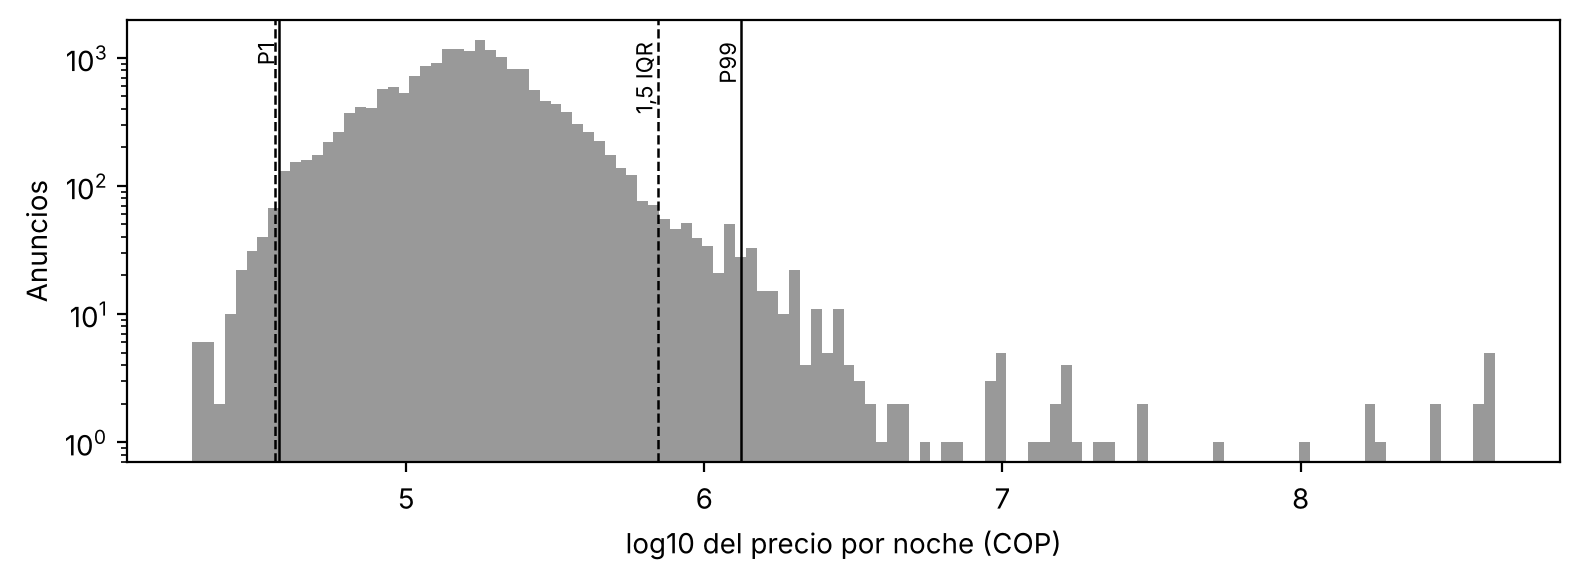

In [11]:
# Grafica: precio en escala logaritmica con los umbrales de cada regla
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(np.log10(s.p), bins=120, color="0.6")
for x, nombre, estilo in [(p99, "P99", "-"), (p01, "P1", "-"), (np.exp(q3 + 1.5 * iqr), "1,5 IQR", "--"), (np.exp(q1 - 1.5 * iqr), "", "--")]:
    ax.axvline(np.log10(x), color="k", ls=estilo, lw=0.9)
    ax.text(np.log10(x), ax.get_ylim()[1] * 0.92, nombre, rotation=90, va="top", ha="right", fontsize=8)
ax.set_xlabel("log10 del precio por noche (COP)"); ax.set_ylabel("Anuncios"); ax.set_yscale("log")
plt.tight_layout(); plt.show()

### 1.d Interrelaciones entre campos que no deberían existir para el estudio

In [12]:
# El precio depende de las noches minimas: estancia mensual (28 noches o mas) frente a estancia corta
v = jun[jun.p.notna() & (jun.p <= p99)]
mensual = v.minimum_nights >= 28
g = v[v.room_type == "Entire home/apt"].groupby(["neighbourhood_cleansed", mensual]).p.median().unstack().dropna()
pd.Series({"% de anuncios con 28 noches o mas": round(mensual.mean() * 100, 1),
           "% de anuncios con mas de 7 noches minimas": round((v.minimum_nights > 7).mean() * 100, 1),
           "mediana por noche, estancia mensual (COP)": round(v[mensual].p.median()),
           "mediana por noche, estancia corta (COP)": round(v[~mensual].p.median()),
           "razon mensual / corta en viviendas completas (mediana entre localidades)": round((g[True] / g[False]).median(), 3),
           "% de cotizaciones con noches cotizadas = noches minimas": round((v.noches_cotizadas == v.minimum_nights).mean() * 100, 1)})

% de anuncios con 28 noches o mas                                               17.600
% de anuncios con mas de 7 noches minimas                                       20.200
mediana por noche, estancia mensual (COP)                                   107399.000
mediana por noche, estancia corta (COP)                                     170000.000
razon mensual / corta en viviendas completas (mediana entre localidades)         0.775
% de cotizaciones con noches cotizadas = noches minimas                         96.500
dtype: float64

In [13]:
# Campos de reputacion y actividad: relacion con el precio (Spearman) y disponibilidad para un anuncio sin resenas
rep = ["number_of_reviews", "number_of_reviews_ltm", "review_scores_rating", "reviews_per_month", "estimated_occupancy_l365d", "availability_365"]
fis = ["accommodates", "bedrooms", "beds", "bathrooms_count", "minimum_nights"]
tabla = pd.DataFrame({"spearman con el precio": v[rep + fis].corrwith(v.p, method="spearman").round(2),
                      "% vacio en anuncios sin resenas": (v.loc[v.number_of_reviews == 0, rep + fis].isna().mean() * 100).round(1)})
tabla["grupo"] = ["reputacion"] * len(rep) + ["formulario"] * len(fis)
print(f"Anuncios sin ninguna resena: {(v.number_of_reviews == 0).mean() * 100:.1f} % | sin resenas en 12 meses: {(v.number_of_reviews_ltm == 0).mean() * 100:.1f} %")
tabla

Anuncios sin ninguna resena: 21.7 % | sin resenas en 12 meses: 35.9 %


,spearman con el precio,% vacio en anuncios sin resenas,grupo
number_of_reviews,0.11,0.0,reputacion
number_of_reviews_ltm,0.09,0.0,reputacion
review_scores_rating,0.06,100.0,reputacion
reviews_per_month,0.06,100.0,reputacion
estimated_occupancy_l365d,0.07,0.0,reputacion
availability_365,-0.04,0.0,reputacion
accommodates,0.50,0.0,formulario
bedrooms,0.31,26.2,formulario
beds,0.36,1.6,formulario
bathrooms_count,0.34,0.2,formulario


In [14]:
# Anuncios que no son independientes: varios del mismo anfitrion y copias casi identicas
por_host = v.groupby("host_id").id.transform("size")
clave = ["host_id", "neighbourhood_cleansed", "room_type", "accommodates", "bedrooms", "beds", "bathrooms_text", "p"]
pd.Series({"anfitriones": v.host_id.nunique(),
           "% de anuncios cuyo anfitrion tiene 2 o mas en el archivo": round((por_host >= 2).mean() * 100, 1),
           "% de anuncios cuyo anfitrion tiene 10 o mas": round((por_host >= 10).mean() * 100, 1),
           "anuncios que repiten anfitrion, localidad, tipo, capacidad y precio de otro": int(v.duplicated(clave, keep="first").sum()),
           "id duplicados": int(jun.id.duplicated().sum()),
           "host_listings_count distinto de calculated_host_listings_count (%)": round((jun.host_listings_count != jun.calculated_host_listings_count).mean() * 100, 1)})

anfitriones                                                                    8160.0
% de anuncios cuyo anfitrion tiene 2 o mas en el archivo                         69.0
% de anuncios cuyo anfitrion tiene 10 o mas                                      32.3
anuncios que repiten anfitrion, localidad, tipo, capacidad y precio de otro    1678.0
id duplicados                                                                     0.0
host_listings_count distinto de calculated_host_listings_count (%)               35.2
dtype: float64

## 2. Selección y aplicación de las técnicas de limpieza

### 2.1 Eliminación: cascada de registros hasta la base de modelado

In [15]:
# Base de modelado con las reglas del equipo: precio valido, hasta P99 y localidades con al menos 500 anuncios
jf = jun[(jun.p > 0) & (jun.p <= p99)]
conteo = jf.neighbourhood_cleansed.value_counts()
loc9 = sorted(conteo[conteo >= 500].index)
con_precio = jun[jun.p.notna() & jun.neighbourhood_cleansed.isin(loc9)].copy()   # incluye los extremos altos
# Particiones para validacion cruzada: 5 grupos por anfitrion, para que sus anuncios no queden a ambos lados
con_precio["pliegue"] = -1
for k, (_, i_val) in enumerate(GroupKFold(n_splits=5).split(con_precio, groups=con_precio.host_id)):
    con_precio.iloc[i_val, con_precio.columns.get_loc("pliegue")] = k
fj = con_precio[con_precio.p <= p99].copy()
print("Localidades habilitadas:", loc9)
print(f"Base de modelado: {len(fj):,} anuncios de {fj.host_id.nunique():,} anfitriones")

Localidades habilitadas: ['Barrios Unidos', 'Candelaria', 'Chapinero', 'Engativa', 'Fontibon', 'Santa Fe', 'Suba', 'Teusaquillo', 'Usaquen']
Base de modelado: 17,749 anuncios de 7,571 anfitriones


In [16]:
# Cascada de registros
a = jun[jun.p.notna()]; b = a[a.p <= p99]; c = b[b.neighbourhood_cleansed.isin(loc9)]
pd.Series({"anuncios en el archivo": len(jun), "sin precio": len(jun) - len(a), "precio mayor a P99": len(a) - len(b),
           "fuera de las 9 localidades": len(b) - len(c), "base de modelado": len(c), "% conservado": round(len(c) / len(jun) * 100, 1)})

anuncios en el archivo        19187.0
sin precio                      195.0
precio mayor a P99              190.0
fuera de las 9 localidades     1053.0
base de modelado              17749.0
% conservado                     92.5
dtype: float64

In [17]:
# Lo que se pierde al excluir las localidades con menos de 500 anuncios
fuera = jf[~jf.neighbourhood_cleansed.isin(loc9)]
print(f"Anuncios: {len(fuera):,} ({len(fuera) / len(jf) * 100:.1f} % de los que tienen precio valido) en {fuera.neighbourhood_cleansed.nunique()} localidades")
print(f"De anfitriones pequenos: {fuera.pequeno.mean() * 100:.1f} % (en la base: {fj.pequeno.mean() * 100:.1f} %)")
conteo[conteo < 500]

Anuncios: 1,053 (5.6 % de los que tienen precio valido) en 11 localidades
De anfitriones pequenos: 58.1 % (en la base: 40.3 %)


neighbourhood_cleansed
Kennedy               307
Puente Aranda         231
Los Martires          181
Antonio Nariño         86
San Cristobal          79
Rafael Uribe Uribe     73
Ciudad Bolivar         41
Bosa                   25
Tunjuelito             16
Usme                   10
Sumapaz                 4
Name: count, dtype: int64

### 2.2 Vacíos en la base de modelado y su mecanismo

In [18]:
# Vacios en las variables del modelo dentro de la base
cols = ["neighbourhood_cleansed", "room_type", "property_type", "accommodates", "bedrooms", "beds", "bathrooms_count",
        "minimum_nights", "amenities", "latitude", "longitude"]
falt = pd.DataFrame({"vacios": fj[cols].isna().sum(), "%": (fj[cols].isna().mean() * 100).round(2)})
print(f"Filas con algun vacio: {fj[cols].isna().any(axis=1).sum():,} ({fj[cols].isna().any(axis=1).mean() * 100:.1f} %)")
falt[falt.vacios > 0]

Filas con algun vacio: 2,968 (16.7 %)


,vacios,%
bedrooms,2679,15.09
beds,271,1.53
bathrooms_count,29,0.16
minimum_nights,4,0.02


In [19]:
# El vacio de habitaciones no es aleatorio: perfil de los anuncios con y sin dato
fj["sin_habitaciones"] = fj.bedrooms.isna()
perfil_h = fj.groupby("sin_habitaciones").agg(
    anuncios=("p", "size"), precio_mediano=("p", "median"), huespedes_promedio=("accommodates", "mean"),
    pct_vivienda_completa=("room_type", lambda x: (x == "Entire home/apt").mean() * 100),
    pct_anfitrion_pequeno=("pequeno", lambda x: x.mean() * 100)).round(1)
print("Proporcion sin dato segun huespedes:", fj.groupby(fj.accommodates.clip(upper=5)).sin_habitaciones.mean().round(3).to_dict())
print("Proporcion sin dato segun tipo:", fj.groupby("room_type").sin_habitaciones.mean().round(3).to_dict())
print("Valor minimo de habitaciones registrado en junio:", fj.bedrooms.min())
perfil_h

Proporcion sin dato segun huespedes: {1: 0.621, 2: 0.175, 3: 0.057, 4: 0.046, 5: 0.017}
Proporcion sin dato segun tipo: {'Entire home/apt': 0.026, 'Hotel room': 0.0, 'Private room': 0.488, 'Shared room': 0.448}
Valor minimo de habitaciones registrado en junio: 1.0


,anuncios,precio_mediano,huespedes_promedio,pct_vivienda_completa,pct_anfitrion_pequeno
sin_habitaciones,,,,,
False,15070,175742.0,3.3,83.4,38.1
True,2679,84447.5,1.9,12.4,52.6


### 2.3 Comparación de técnicas de imputación por enmascaramiento

In [20]:
# Se ocultan habitaciones conocidas con el mismo perfil (tipo y huespedes) de los vacios reales y se imputan con cada tecnica.
# Se repite 100 veces; cada tecnica se ajusta solo con los anuncios que quedan visibles.
conocidos = fj[~fj.sin_habitaciones & fj.beds.notna() & fj.bathrooms_count.notna()].copy()
vacios = fj[fj.sin_habitaciones]
estrato = lambda d: list(zip(d.room_type == "Entire home/apt", d.accommodates.clip(upper=6)))
conocidos["estrato"] = estrato(conocidos)
objetivo = pd.Series(estrato(vacios)).value_counts()
tam = {e: min(n, int(0.5 * (conocidos.estrato == e).sum())) for e, n in objetivo.items()}

def matriz(d, camas_ref):
    camas = d.beds.fillna(d.accommodates.map(camas_ref)).fillna(1)
    return np.column_stack([np.ones(len(d)), d.accommodates, camas, d.bathrooms_count.fillna(1), (d.room_type == "Entire home/apt").astype(float)])

rng = np.random.default_rng(0)
filas = []
for rep in range(100):
    oculto = pd.concat([conocidos[conocidos.estrato == e].sample(n, random_state=int(rng.integers(1e9))) for e, n in tam.items() if n > 0])
    visible = conocidos.drop(oculto.index)
    y = oculto.bedrooms.values
    beta, *_ = np.linalg.lstsq(matriz(visible, visible.groupby("accommodates").beds.median()), visible.bedrooms.values, rcond=None)
    bolsas = {a: g.bedrooms.values for a, g in visible.groupby("accommodates")}
    tecnicas = {
        "valor fijo: mediana (regla del equipo)": np.full(len(y), visible.bedrooms.median()),
        "mediana segun huespedes": oculto.accommodates.map(visible.groupby("accommodates").bedrooms.median()).fillna(visible.bedrooms.median()).values,
        "regresion lineal (huespedes, camas, banos, tipo)": np.clip(np.round(matriz(oculto, visible.groupby("accommodates").beds.median()) @ beta), 0, None),
        "aleatoria segun huespedes": np.array([rng.choice(bolsas.get(a, visible.bedrooms.values)) for a in oculto.accommodates]),
    }
    for k, val in tecnicas.items():
        filas.append({"tecnica": k, "error absoluto medio": np.abs(val - y).mean(), "% exacto": (val == y).mean() * 100})
comp = pd.DataFrame(filas).groupby("tecnica", sort=False).agg(["mean", "std"]).round(2)
print(f"Anuncios ocultos por repeticion: {len(oculto):,} | habitacion privada o compartida entre los ocultos: {(~oculto.room_type.eq('Entire home/apt')).mean() * 100:.1f} % "
      f"(entre los vacios reales: {(~vacios.room_type.eq('Entire home/apt')).mean() * 100:.1f} %)")
print("Habitaciones entre los ocultos (%):", (oculto.bedrooms.value_counts(normalize=True).sort_index().head(4) * 100).round(1).to_dict())
comp

Anuncios ocultos por repeticion: 1,452 | habitacion privada o compartida entre los ocultos: 77.1 % (entre los vacios reales: 87.6 %)
Habitaciones entre los ocultos (%): {1.0: 85.9, 2.0: 8.4, 3.0: 1.9, 4.0: 0.7}


error absoluto medio       % exacto      
                                                                 mean   std     mean   std
tecnica                                                                                   
valor fijo: mediana (regla del equipo)                           0.51  0.04    85.24  0.61
mediana segun huespedes                                          0.51  0.04    81.52  0.68
regresion lineal (huespedes, camas, banos, tipo)                 0.42  0.03    79.49  2.06
aleatoria segun huespedes                                        0.61  0.04    79.42  0.76

## 3. Resultados del proceso de limpieza

### 3.1 Efecto de cada decisión en el error del modelo (validación cruzada dentro de junio)

In [21]:
# Variables y modelo final, evaluados con validacion cruzada dentro de junio
AMENIDADES = {"tiene_wifi": r"wifi", "tiene_parqueadero": r"parking", "tiene_ascensor": r"elevator", "tiene_zona_trabajo": r"workspace",
              "tiene_agua_caliente": r"^hot water$", "tiene_jacuzzi": r"hot tub", "tiene_cocina": r"^kitchen$", "tiene_lavadora": r"washer",
              "tiene_aire_acondicionado": r"air conditioning|^ac ", "tiene_piscina": r"pool", "tiene_gimnasio": r"gym", "tiene_vista": r"view",
              "tiene_balcon": r"patio or balcony", "tiene_tv": r"^tv|hdtv", "tiene_autocheckin": r"self check-in", "acepta_mascotas": r"pets allowed"}
CATEGORICAS = ["neighbourhood_cleansed", "room_type", "tipologia"]
NUMERICAS = ["accommodates", "bedrooms", "beds", "bathrooms_count", "noches_minimas"]
BINARIAS = ["is_shared_bathroom"] + list(AMENIDADES) + ["estancia_mensual"]
PARAMETROS = {"n_estimators": 1500, "num_leaves": 63, "max_depth": -1, "min_child_samples": 20, "subsample": 0.8, "subsample_freq": 1,
              "colsample_bytree": 0.7, "reg_lambda": 0.0, "reg_alpha": 0.0, "objective": "l1", "learning_rate": 0.02}

def variables(d, tipologias):
    d = d.copy()
    d["log_p"] = np.log(d.p)
    d["is_shared_bathroom"] = d.bathrooms_text.fillna("").str.lower().str.contains("shared").astype(int)
    listas = d.amenities.fillna("[]").map(lambda s: [a.lower() for a in json.loads(s)] if s.startswith("[") else [])
    for col, patron in AMENIDADES.items():
        pat = re.compile(patron)
        d[col] = listas.map(lambda lst: int(any(pat.search(a) for a in lst)))
    d["noches_minimas"] = d.minimum_nights.fillna(1).clip(1, 30)          # vacio = moda (1); tope en 30
    d["estancia_mensual"] = (d.noches_minimas >= 28).astype(int)
    d["tipologia"] = d.property_type.where(d.property_type.isin(tipologias), "Other")
    return d

def armar_modelo(categoricas=CATEGORICAS, numericas=NUMERICAS, binarias=BINARIAS):
    prep = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categoricas),
                              ("num", SimpleImputer(strategy="median"), numericas), ("bin", SimpleImputer(strategy="most_frequent"), binarias)])
    return Pipeline([("prep", prep), ("modelo", lgb.LGBMRegressor(verbose=-1, random_state=0, **PARAMETROS))])

def validar(entrenamiento=None, transformar=None, columnas=None, guardar=None):
    # Devuelve el error porcentual absoluto de cada anuncio de la base cuando queda fuera del entrenamiento.
    # entrenamiento: regla que define las filas de entrenamiento; transformar: regla que cambia valores en entrenamiento y validacion
    cats, nums, bins = columnas or (CATEGORICAS, NUMERICAS, BINARIAS)
    error = pd.Series(np.nan, index=fj.index)
    for k in range(5):
        tr, te = con_precio[con_precio.pliegue != k], fj[fj.pliegue == k]
        tr = entrenamiento(tr) if entrenamiento else tr[tr.p <= p99]
        if transformar:
            tr, te = transformar(tr, te)
        vc = tr.property_type.value_counts()
        tipologias = sorted(vc[vc >= 50].index)
        tr, te = variables(tr, tipologias), variables(te, tipologias)
        modelo = armar_modelo(cats, nums, bins).fit(tr[cats + nums + bins], tr.log_p)
        error[te.index] = np.abs(np.exp(modelo.predict(te[cats + nums + bins])) - te.p) / te.p * 100
        if guardar is not None:
            guardar.append((modelo, te))
    return error

# Intervalo de 95 % para una diferencia de MdAPE: bootstrap pareado que remuestrea anfitriones completos
rng_boot = np.random.default_rng(1)
def mediana_ponderada(v, w):
    o = np.argsort(v)
    c = np.cumsum(w[o])
    return v[o][np.searchsorted(c, c[-1] / 2)]

def ic_diferencia(err_a, err_b, filas=None, B=1000):
    filas = fj.index if filas is None else filas
    a, b = err_a.loc[filas].values, err_b.loc[filas].values
    codigos = pd.factorize(fj.loc[filas, "host_id"])[0]
    H = codigos.max() + 1
    d = np.empty(B)
    for i in range(B):
        w = rng_boot.multinomial(H, np.full(H, 1 / H))[codigos].astype(float)
        d[i] = mediana_ponderada(a, w) - mediana_ponderada(b, w)
    return np.median(a) - np.median(b), np.percentile(d, 2.5), np.percentile(d, 97.5)

In [22]:
# Variantes de limpieza. Todas se evaluan sobre los mismos anuncios de la base cuando quedan fuera del entrenamiento
VACIOS = ["bedrooms", "beds", "bathrooms_count", "minimum_nights"]

def recorte_por_tipo(tr):
    lo = tr.groupby("room_type").p.transform(lambda x: x.quantile(0.01))
    hi = tr.groupby("room_type").p.transform(lambda x: x.quantile(0.99))
    return tr[(tr.p >= lo) & (tr.p <= hi)]

def con_regresion(tr, te):
    con = tr[tr.bedrooms.notna() & tr.beds.notna() & tr.bathrooms_count.notna()]
    ref = con.groupby("accommodates").beds.median()
    beta, *_ = np.linalg.lstsq(matriz(con, ref), con.bedrooms.values, rcond=None)
    salida = []
    for d in (tr, te):
        d = d.copy(); falta = d.bedrooms.isna()
        d.loc[falta, "bedrooms"] = np.clip(np.round(matriz(d[falta], ref) @ beta), 0, None)
        salida.append(d)
    return salida

def con_aleatoria(tr, te):
    r = np.random.default_rng(0)
    con = tr[tr.bedrooms.notna()]
    bolsas = {a: g.bedrooms.values for a, g in con.groupby("accommodates")}
    salida = []
    for d in (tr, te):
        d = d.copy(); falta = d.bedrooms.isna()
        d.loc[falta, "bedrooms"] = [r.choice(bolsas.get(a, con.bedrooms.values)) for a in d.loc[falta, "accommodates"]]
        salida.append(d)
    return salida

def con_topes(tr, te):
    topes = {c: tr[c].quantile(0.99) for c in ["bedrooms", "beds", "bathrooms_count"]}
    return [d.assign(**{c: d[c].clip(upper=t) for c, t in topes.items()}) for d in (tr, te)]

variantes = {
    "0. Regla del equipo: recorte en P99 y mediana": {},
    "1. Sin recortar extremos altos": {"entrenamiento": lambda tr: tr},
    "2. Recorte en P1 y P99 dentro de cada tipo (Guia 2)": {"entrenamiento": recorte_por_tipo},
    "3. Recorte en P1 y P99 globales": {"entrenamiento": lambda tr: tr[(tr.p >= p01) & (tr.p <= p99)]},
    "4. Eliminacion general de filas con vacios": {"entrenamiento": lambda tr: tr[tr.p <= p99].dropna(subset=VACIOS)},
    "5. Habitaciones por regresion": {"transformar": con_regresion},
    "6. Habitaciones por imputacion aleatoria": {"transformar": con_aleatoria},
    "7. Tope en P99 para habitaciones, camas y banos": {"transformar": con_topes},
}
errores = {k: validar(**v) for k, v in variantes.items()}
base = errores["0. Regla del equipo: recorte en P99 y mediana"]
tam_entrenamiento = {"0.": len(fj), "1.": len(con_precio), "2.": len(recorte_por_tipo(con_precio)), "3.": int(((con_precio.p >= p01) & (con_precio.p <= p99)).sum()),
                     "4.": len(fj.dropna(subset=VACIOS)), "5.": len(fj), "6.": len(fj), "7.": len(fj)}
filas = {}
for k, e in errores.items():
    d, lo, hi = ic_diferencia(e, base)
    filas[k] = {"anuncios disponibles para entrenar": tam_entrenamiento[k[:2]], "MdAPE (%)": round(e.median(), 2),
                "MdAPE anfitriones pequenos (%)": round(e[fj.pequeno].median(), 2),
                "diferencia (pp)": "referencia" if k.startswith("0.") else f"{d:+.2f}", "IC 95 %": "" if k.startswith("0.") else f"[{lo:.2f}, {hi:.2f}]"}
pd.DataFrame(filas).T

,anuncios disponibles para entrenar,MdAPE (%),MdAPE anfitriones pequenos (%),diferencia (pp),IC 95 %
0. Regla del equipo: recorte en P99 y mediana,17749,21.24,22.03,referencia,
1. Sin recortar extremos altos,17933,21.24,21.99,+0.00,"[-0.23, 0.18]"
2. Recorte en P1 y P99 dentro de cada tipo (Guia 2),17590,21.27,21.82,+0.04,"[-0.23, 0.20]"
3. Recorte en P1 y P99 globales,17610,21.25,22.11,+0.02,"[-0.21, 0.20]"
4. Eliminacion general de filas con vacios,14781,21.57,22.17,+0.34,"[-0.01, 0.71]"
5. Habitaciones por regresion,17749,21.13,21.94,-0.11,"[-0.27, 0.07]"
6. Habitaciones por imputacion aleatoria,17749,21.25,21.99,+0.01,"[-0.20, 0.14]"
"7. Tope en P99 para habitaciones, camas y banos",17749,21.11,21.81,-0.13,"[-0.31, 0.02]"


In [23]:
# Filtros de poblacion de las guias 2 y 3: resena en 12 meses y hasta 7 noches minimas.
# Para cada poblacion se compara entrenar con toda la base frente a entrenar solo con esa poblacion
poblaciones = {
    "con resena en los ultimos 12 meses (Guia 2)": (fj.number_of_reviews_ltm > 0, lambda tr: tr[(tr.p <= p99) & (tr.number_of_reviews_ltm > 0)]),
    "hasta 7 noches minimas (Guia 3, riesgo 18)": (fj.minimum_nights <= 7, lambda tr: tr[(tr.p <= p99) & (tr.minimum_nights <= 7)]),
}
filas = {}
for k, (mascara, regla) in poblaciones.items():
    e = validar(entrenamiento=regla)
    idx = fj.index[mascara]
    d, lo, hi = ic_diferencia(e, base, idx)
    filas[k] = {"anuncios de la poblacion": int(mascara.sum()), "% de la base": round(mascara.mean() * 100, 1),
                "% de anfitriones pequenos": round(fj.pequeno[mascara].mean() * 100, 1),
                "anuncios de anfitriones pequenos que quedan fuera": int((fj.pequeno & ~mascara).sum()),
                "% de los anuncios de pequenos que quedan fuera": round((fj.pequeno & ~mascara).sum() / fj.pequeno.sum() * 100, 1),
                "MdAPE entrenando con toda la base (%)": round(base[idx].median(), 2), "MdAPE entrenando solo con la poblacion (%)": round(e[idx].median(), 2),
                "diferencia (pp)": f"{d:+.2f}", "IC 95 %": f"[{lo:.2f}, {hi:.2f}]",
                "MdAPE del modelo general en los excluidos (%)": round(base[fj.index[~mascara]].median(), 2)}
pd.DataFrame(filas)

,con resena en los ultimos 12 meses (Guia 2),"hasta 7 noches minimas (Guia 3, riesgo 18)"
anuncios de la poblacion,11454,14246
% de la base,64.5,80.3
% de anfitriones pequenos,35.6,32.7
anuncios de anfitriones pequenos que quedan fuera,3076,2493
% de los anuncios de pequenos que quedan fuera,43.0,34.9
MdAPE entrenando con toda la base (%),19.75,20.36
MdAPE entrenando solo con la poblacion (%),19.41,20.55
diferencia (pp),-0.35,+0.20
IC 95 %,"[-0.74, 0.03]","[-0.05, 0.47]"
MdAPE del modelo general en los excluidos (%),24.15,25.13


In [24]:
# Linea base: mediana por localidad y tipo de alojamiento, con las mismas particiones
def linea_base(entrenamiento=None):
    error = pd.Series(np.nan, index=fj.index)
    for k in range(5):
        tr, te = con_precio[con_precio.pliegue != k], fj[fj.pliegue == k]
        tr = entrenamiento(tr) if entrenamiento else tr[tr.p <= p99]
        ref = tr.groupby(["neighbourhood_cleansed", "room_type"]).p.median().rename("ref")
        r = te.join(ref, on=["neighbourhood_cleansed", "room_type"]).ref
        error[te.index] = (r - te.p).abs() / te.p * 100
    return error
lb, lb_sin = linea_base(), linea_base(lambda tr: tr)
grupos = lambda d: d.groupby(["neighbourhood_cleansed", "room_type"]).p
pd.DataFrame({"con recorte en P99": {"MdAPE de la mediana por localidad y tipo (%)": round(lb.median(), 2), "limite de adopcion de la Guia 2: 0,90 veces (%)": round(0.9 * lb.median(), 2),
                                    "promedio / mediana del grupo (mediana entre grupos)": round((grupos(fj).mean() / grupos(fj).median()).median(), 2)},
              "sin recorte": {"MdAPE de la mediana por localidad y tipo (%)": round(lb_sin.median(), 2), "limite de adopcion de la Guia 2: 0,90 veces (%)": round(0.9 * lb_sin.median(), 2),
                              "promedio / mediana del grupo (mediana entre grupos)": round((grupos(con_precio).mean() / grupos(con_precio).median()).median(), 2)}})

,con recorte en P99,sin recorte
MdAPE de la mediana por localidad y tipo (%),29.79,30.00
"limite de adopcion de la Guia 2: 0,90 veces (%)",26.81,27.00
promedio / mediana del grupo (mediana entre grupos),1.20,1.31


### 3.2 Error por segmento después de la limpieza

In [25]:
# Error del modelo con la regla del equipo, por segmento de la base
segmentos = {"todos": fj.p > 0, "anfitriones pequenos": fj.pequeno, "anfitriones con 3 anuncios o mas": ~fj.pequeno,
             "estancia mensual (28 noches o mas)": fj.minimum_nights >= 28, "estancia corta": ~(fj.minimum_nights >= 28),
             "habitacion privada": fj.room_type == "Private room", "vivienda completa": fj.room_type == "Entire home/apt",
             "sin dato de habitaciones": fj.sin_habitaciones, "sin resenas": fj.number_of_reviews == 0}
pd.DataFrame({k: {"anuncios": int(f.sum()), "MdAPE del modelo (%)": round(base[f].median(), 2), "MdAPE de la linea base (%)": round(lb[f].median(), 2)} for k, f in segmentos.items()}).T

,anuncios,MdAPE del modelo (%),MdAPE de la linea base (%)
todos,17749.0,21.24,29.79
anfitriones pequenos,7150.0,22.03,31.03
anfitriones con 3 anuncios o mas,10599.0,20.69,29.10
estancia mensual (28 noches o mas),3041.0,25.59,45.13
estancia corta,14708.0,20.49,27.71
habitacion privada,4700.0,24.92,35.26
vivienda completa,12901.0,19.96,28.27
sin dato de habitaciones,2679.0,23.11,33.33
sin resenas,3760.0,24.46,36.19
